
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/12_Lab_PinnsI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pylab as plt
import plotly.graph_objects as go
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display


#Diferenciación automática

In [2]:
#EJEMPLO DE CLASE

def suma(a, da, b, db):
  return a+b, da+db
#y=2x=x+x
x=1
suma(x,1,x,1)

#después hizo el ejemplo para hacer derivadas por ejemplo de sin(x^2)... bastante interesante realmente

(2, 2)

In [3]:
def suma(a, da, b, db):
  return a+b, da+db

def producto(a, da, b, db):
  return a*b, a*db + da*b

def division(a, da, b, db):
  return a/b, (b*da - a*db)/(b**2)

def seno(a, da):
  return np.sin(a), da*np.cos(a)

def coseno(a, da):
  return np.cos(a), -da*np.sin(a)


def tanhiperbolica(a, da):
    valor = np.tanh(a)
    return valor, (1 - valor**2)*da

#EJEMPLO PARA YO HACER EN CLASE
$$
f(x)=\sin(\cos(x^2))+\tan(\sin(x^3))
$$

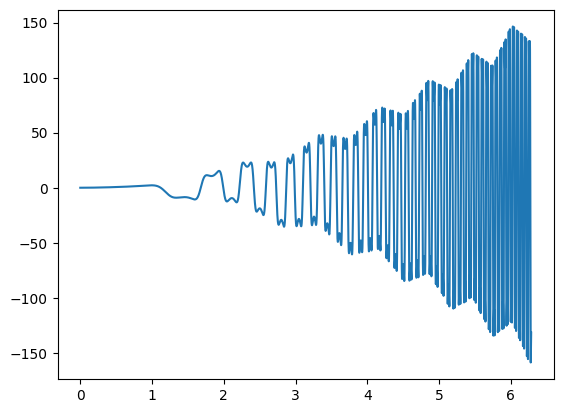

In [4]:
x = np.linspace(0, 2*np.pi, 10000)
u1 , du1 = producto(x,1,x,1)
u2_1 , du2_1 = producto(x,1,x,1)  #acá lo dividí en varias partes, primero el x*x y luego x^2 * x toca después
u2_2 , du2_2 =producto(u2_1 , du2_1 , x , 1)  #con este en teoría llego a x^3... i guess
c1 , dc1 = coseno(u1 , du1)  #coseno de la primer parte
c2 , dc2 = seno(u2_2 , du2_2)   #sin de la segunda parte
m1 , dm1 = seno(c1 , dc1)  #en teoría esta ya es la primer parte
m2 , dm2 =division(*seno(c2 , dc2),*coseno(c2 , dc2))  #el profe nos recomendó hacer la de la tangente como un cociente
f , df = suma(m1 , dm1 , m2 , dm2)

plt.plot(x, df)  ##creo que me dio bien, ahora lo que haré será compararla con la real

Computemos la deriva de:

$f(x) = x^2$


$f(x) = (2x+1)^2$

In [5]:
x = 2.2

In [6]:
derivadaX = producto(x, 1, x, 1)
derivadaX

(4.840000000000001, 4.4)

In [7]:
u, du = producto(2, 0, x, 1)
c, dc = suma(u, du, 1, 0)
producto(c, dc, c, dc)

(29.160000000000004, 21.6)

In [8]:
x = np.linspace(0, 2*np.pi)

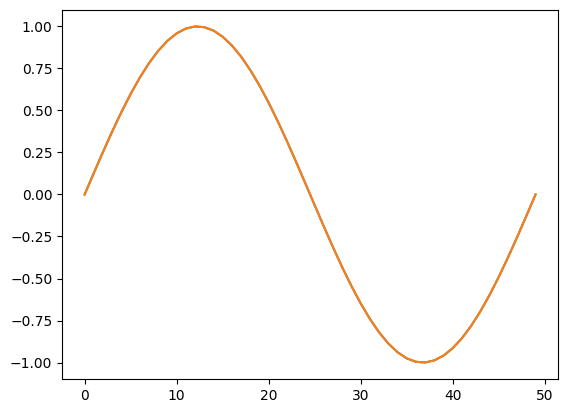

In [9]:
plt.plot(np.sin(x))
plt.plot(seno(x, 1)[0])

$
f(x)=\sin\!\bigl(\cos(x^2)\bigr),
$

$
u=x^2,\qquad u'=2x,
$

$
v=\cos(u),\qquad v'=-\sin(u)\,u',
$


$
f=\sin(v),\qquad f'=\cos(v)\,v'.
$


$
f'(x)=-2x\,\sin(x^2)\,\cos\!\bigl(\cos(x^2)\bigr).
$

In [10]:
x = np.linspace(0, 2*np.pi, 10000)
u, du = producto(x, 1, x, 1)
c, dc = coseno(u, du)
r, dr = seno(c, dc)

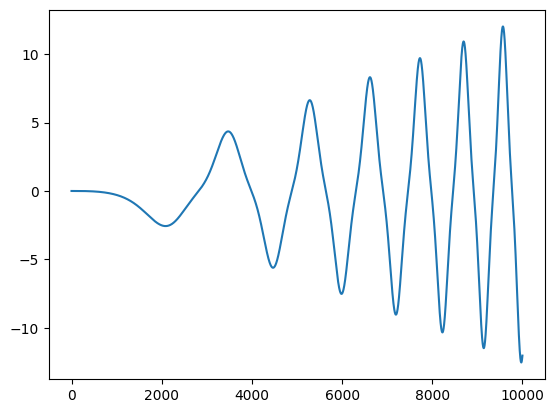

In [11]:
plt.plot(dr)

Supongamos que tenemos dos conectadas y queremos computar una diferenciacion automática cuyas funciones de activación son tanh:

\begin{equation}
\frac{da_2}{dx}
=
\frac{da_2}{dz_2}
\frac{dz_2}{da_1}
\frac{da_1}{dz_1}
\frac{dz_1}{dx}
=
(1-\tanh Z_2^2)\,w_2\,(1-\tanh Z_1^2)\,w_1.
\end{equation}



In [12]:
x = 0.8
w = 0.1
b = 0.1

z = w*x + b
a1 = np.tanh(z)

z2 = w*a1 + b
a2 = np.tanh(z2)

derivada = (1-(np.tanh( z2))**2) * (1-(np.tanh( z))**2)*w**2
derivada

np.float64(0.009549719627467191)

In [13]:
t1, dt1 = producto(w, 0, x, 1)
z, dz = suma(t1, dt1, b, 0)
a1, da1 = tanhiperbolica(z, dz)

t2, dt2 = producto(w, 0, a1, da1)
z2, dz2 = suma(t2, dt2, b, 0)
a2, da2 = tanhiperbolica(z2, dz2)
a2, da2




(np.float64(0.11726608605144122), np.float64(0.009549719627467191))

In [14]:
def dneurona(x, dx, w, b):
  t1, dt1 = producto(w, 0, x, dx)
  z, dz = suma(t1, dt1, b, 0)
  a1, da1 = tanhiperbolica(z, dz)
  return a1, da1

In [15]:
a1, da1 = dneurona(x, 1, w, b)
a2, da2 = dneurona(a1, da1, w, b)
a2, da2

(np.float64(0.11726608605144122), np.float64(0.009549719627467191))

### Difusión de calor en una placa cuadrada

Considere una placa homogénea de lado $L$, sin fuentes internas
de calor y con temperatura uniforme a través de su espesor.
Su difusividad térmica es constante:

$$
\alpha=\frac{k}{\rho c_p},
$$

donde $k$ es la conductividad térmica, $\rho$ la densidad y
$c_p$ el calor específico.

Determine la temperatura $T(x,y,t)$ en el dominio
$(x,y)\in(0,L)^2$, para $t>0$, mediante la ecuación de calor:

$$
\frac{\partial T}{\partial t}
=
\alpha\left(
\frac{\partial^2T}{\partial x^2}
+
\frac{\partial^2T}{\partial y^2}
\right).
$$

Los cuatro bordes permanecen a temperatura constante $T_b$:

$$
T(0,y,t)=T(L,y,t)=T(x,0,t)=T(x,L,t)=T_b.
$$

La temperatura inicial es:

$$
T(x,y,0)=T_b+\Delta T
\sin\left(\frac{\pi x}{L}\right)
\sin\left(\frac{\pi y}{L}\right),
$$

donde $\Delta T>0$ es la diferencia inicial entre la temperatura
del centro y la de los bordes.

Aproximar $T(x,y,t)$ mediante una PINN,
minimizando el residual de la ecuación y los errores en las
condiciones iniciales y de frontera. Comparar el resultado
con la solución analítica:

$$
T(x,y,t)=T_b+\Delta T
e^{-2\alpha\pi^2t/L^2}
\sin\left(\frac{\pi x}{L}\right)
\sin\left(\frac{\pi y}{L}\right).
$$

In [16]:
Lx = 1.0       # Longitud en x [m]
Ly = 1.0       # Longitud en y [m]
Tb = 300     # Temperatura fija de los bordes [°C]
delta_T = 100.0 # Diferencia inicial centro-bordes [°C]

alpha = 1e-4  # Difusividad térmica [m²/s]
params = {'Lx': Lx, 'Ly': Ly, 'Tb': Tb, "delta":delta_T ,'alpha': alpha}

In [17]:
def T(x, y, t, **params):

  Lx = params['Lx']
  Ly = params['Ly']
  Tb = params['Tb']
  alpha = params['alpha']
  u = np.sin(np.pi*x/Lx)*np.sin(np.pi*y/Ly)
  return Tb + delta_T* np.exp(-2*alpha*np.pi**2*t/(Lx*Ly))*u


In [18]:
nx, ny = 30, 30
tiempo_final = 500.0

x = np.linspace(0, params["Lx"], nx)
y = np.linspace(0, params["Ly"], ny)
dx = x[1] - x[0]
dy = y[1] - y[0]

# Límite de estabilidad para diferencias finitas con Euler explícito
dt_max = 1 / (
    2 * params["alpha"] * (1 / dx**2 + 1 / dy**2)
)
# Margen de seguridad del 10 %
nt = int(np.ceil(tiempo_final / (0.9 * dt_max))) + 1

t = np.linspace(0, tiempo_final, nt)
dt = t[1] - t[0]
X, Y = np.meshgrid(x, y, indexing="ij")
nx, ny, nt = len(x), len(y), len(t)
Temperatura = np.zeros((nt,nx, ny))

In [19]:
# Tu función T usa delta_T global y Lx*Ly; esta versión usa params y es general
def T_analitica(x, y, t):
    decaimiento = np.exp(-params["alpha"] * np.pi**2 * t * (1/params["Lx"]**2 + 1/params["Ly"]**2))
    return params["Tb"] + params["delta"] * decaimiento * np.sin(np.pi*x/params["Lx"]) * np.sin(np.pi*y/params["Ly"])

# Solución analítica en toda la malla
T_exacta = np.array([T_analitica(X, Y, tk) for tk in t])        # (nt, nx, ny)

# Diferencias finitas (Euler explícito) con el dt que ya calculaste
Temperatura[0] = T_analitica(X, Y, 0)
rx = params["alpha"] * dt / dx**2
ry = params["alpha"] * dt / dy**2
for k in range(nt - 1):
    Tk = Temperatura[k]
    Tn = Tk.copy()
    Tn[1:-1, 1:-1] = (Tk[1:-1, 1:-1]
                      + rx * (Tk[2:, 1:-1] - 2*Tk[1:-1, 1:-1] + Tk[:-2, 1:-1])
                      + ry * (Tk[1:-1, 2:] - 2*Tk[1:-1, 1:-1] + Tk[1:-1, :-2]))
    Tn[0, :] = Tn[-1, :] = Tn[:, 0] = Tn[:, -1] = params["Tb"]   # bordes a Tb
    Temperatura[k + 1] = Tn

print("Error máx. diferencias finitas vs analítica [°C]:", np.abs(Temperatura - T_exacta).max())

Error máx. diferencias finitas vs analítica [°C]: 0.0610349087069153


In [20]:
import numpy as np
import plotly.graph_objects as go


def graficar_planos(
    Temperatura, Lx, Ly,
    tiempos=None,
    n_planos=5,
    opacidad=0.5
):
    nt, nx, ny = Temperatura.shape

    x = np.linspace(0, Lx, nx)
    y = np.linspace(0, Ly, ny)
    X, Y = np.meshgrid(x, y, indexing="ij")

    titulo_t = "Tiempo [s]" if tiempos is not None else "Índice de tiempo"
    tiempos = np.arange(nt) if tiempos is None else np.asarray(tiempos)

    # Seleccionar pocos tiempos, incluyendo el primero y el último.
    indices = np.unique(
        np.linspace(0, nt - 1, min(n_planos, nt), dtype=int)
    )

    # Escala de colores común.
    Tmin = float(np.nanmin(Temperatura))
    Tmax = float(np.nanmax(Temperatura))

    if Tmin == Tmax:
        Tmin -= 0.5
        Tmax += 0.5

    fig = go.Figure()

    for j, k in enumerate(indices):
        fig.add_trace(go.Surface(
            x=np.full(X.shape, tiempos[k], dtype=float),
            y=X,
            z=Y,
            surfacecolor=Temperatura[k],
            colorscale="Jet",
            cmin=Tmin,
            cmax=Tmax,
            opacity=opacidad,
            showscale=(j == 0),
            colorbar=dict(title="Temperatura [°C]"),
            lighting=dict(ambient=1, diffuse=0, specular=0),
            name=f"Temperatura[{k}]",
            hovertemplate=(
                "Tiempo / índice = %{x:.3f}<br>"
                "x = %{y:.3f} m<br>"
                "y = %{z:.3f} m<br>"
                "T = %{surfacecolor:.2f} °C"
                "<extra>%{fullData.name}</extra>"
            )
        ))

    fig.update_layout(
        height=650,
        scene=dict(
            xaxis_title=titulo_t,
            yaxis_title="x [m]",
            zaxis_title="y [m]",
            aspectmode="manual",
            aspectratio=dict(x=1.6, y=1, z=Ly / Lx),
            camera=dict(eye=dict(x=-1.7, y=-1.7, z=0.8))
        ),
        margin=dict(l=0, r=0, b=0, t=30)
    )

    return fig

In [21]:
fig = graficar_planos(
    Temperatura, Lx, Ly,
    n_planos=10,
    opacidad=0.5
)
fig.show()

In [22]:

n_frames =len(Temperatura)# min(100), Temperatura.shape[0])

fig, ax = plt.subplots(figsize=(6, 5))

imagen = ax.imshow(
    Temperatura[0],
    cmap="jet",
    vmin=np.nanmin(Temperatura[:n_frames]),
    vmax=np.nanmax(Temperatura[:n_frames])
)

fig.colorbar(imagen, ax=ax, label="Temperatura [°C]")
titulo = ax.set_title("Temperatura[0]")

def actualizar(i):
    imagen.set_data(Temperatura[i])
    titulo.set_text(f"Temperatura[{i}]")
    return imagen, titulo

animacion = FuncAnimation(
    fig,
    actualizar,
    frames=n_frames,
    interval=1,
    repeat=True
)

plt.close(fig)
display(HTML(animacion.to_jshtml()))

Output hidden; open in https://colab.research.google.com to view.

it 1000: total=7.28e-03 | EDP=3.51e-03 | IC=1.04e-03 | BC=2.73e-03
it 2000: total=2.19e-03 | EDP=1.20e-03 | IC=2.88e-04 | BC=7.00e-04
it 3000: total=2.87e-03 | EDP=6.01e-04 | IC=6.49e-04 | BC=1.62e-03
it 4000: total=4.13e-04 | EDP=2.92e-04 | IC=4.27e-05 | BC=7.74e-05
it 5000: total=3.48e-04 | EDP=1.79e-04 | IC=2.67e-05 | BC=1.43e-04
it 6000: total=2.03e-04 | EDP=1.47e-04 | IC=1.87e-05 | BC=3.73e-05
it 7000: total=1.86e-04 | EDP=9.77e-05 | IC=1.44e-05 | BC=7.40e-05
it 8000: total=1.25e-04 | EDP=9.17e-05 | IC=6.11e-06 | BC=2.69e-05


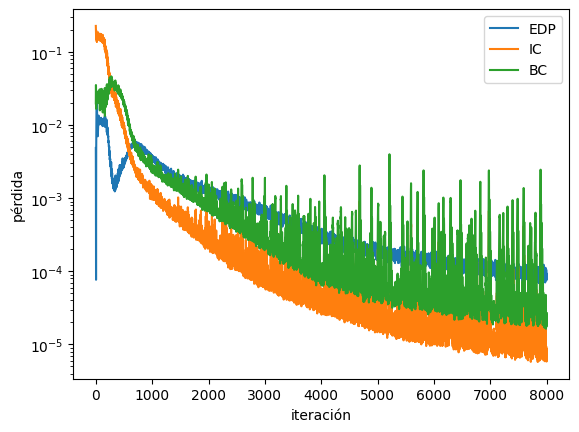

In [23]:
import torch
import torch.nn as nn
torch.manual_seed(0)

# Variables adimensionales: x̂ = x/Lx, ŷ = y/Ly, τ = t/tf, θ = (T - Tb)/ΔT
# La EDP queda: θ_τ = kx θ_x̂x̂ + ky θ_ŷŷ
tf = tiempo_final
kx = params["alpha"] * tf / params["Lx"]**2
ky = params["alpha"] * tf / params["Ly"]**2

class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.red = nn.Sequential(
            nn.Linear(3, 32), nn.Tanh(),
            nn.Linear(32, 32), nn.Tanh(),
            nn.Linear(32, 32), nn.Tanh(),
            nn.Linear(32, 1))
    def forward(self, x, y, tau):
        return self.red(torch.cat([x, y, tau], dim=1))

modelo_pinn = PINN()

def d(f, v):   # derivada de f respecto a v con diferenciación automática
    return torch.autograd.grad(f, v, torch.ones_like(f), create_graph=True)[0]

def residuo(x, y, tau):
    th = modelo_pinn(x, y, tau)
    return d(th, tau) - kx * d(d(th, x), x) - ky * d(d(th, y), y)

def azar(n, grad=False):
    return torch.rand(n, 1, requires_grad=grad)

opt = torch.optim.Adam(modelo_pinn.parameters(), lr=1e-3)
historia = []

for it in range(1, 8001):
    # 1) Residuo de la EDP en puntos interiores
    x, y, tau = azar(2000, True), azar(2000, True), azar(2000, True)
    L_pde = residuo(x, y, tau).pow(2).mean()

    # 2) Condición inicial (τ = 0): θ = sin(πx) sin(πy)
    x0, y0 = azar(500), azar(500)
    th0 = modelo_pinn(x0, y0, torch.zeros_like(x0))
    L_ic = (th0 - torch.sin(np.pi * x0) * torch.sin(np.pi * y0)).pow(2).mean()

    # 3) Fronteras: θ = 0 en x=0, x=1, y=0, y=1
    xb, yb, tb = azar(500), azar(500), azar(500)
    c, u = torch.zeros_like(xb), torch.ones_like(xb)
    L_bc = (modelo_pinn(c, yb, tb).pow(2).mean() + modelo_pinn(u, yb, tb).pow(2).mean()
            + modelo_pinn(xb, c, tb).pow(2).mean() + modelo_pinn(xb, u, tb).pow(2).mean())

    loss = L_pde + L_ic + L_bc
    opt.zero_grad(); loss.backward(); opt.step()
    historia.append([L_pde.item(), L_ic.item(), L_bc.item()])

    if it % 1000 == 0:
        print(f"it {it}: total={loss.item():.2e} | EDP={L_pde.item():.2e} | IC={L_ic.item():.2e} | BC={L_bc.item():.2e}")

historia = np.array(historia)
plt.semilogy(historia[:, 0], label="EDP"); plt.semilogy(historia[:, 1], label="IC"); plt.semilogy(historia[:, 2], label="BC")
plt.xlabel("iteración"); plt.ylabel("pérdida"); plt.legend(); plt.show()

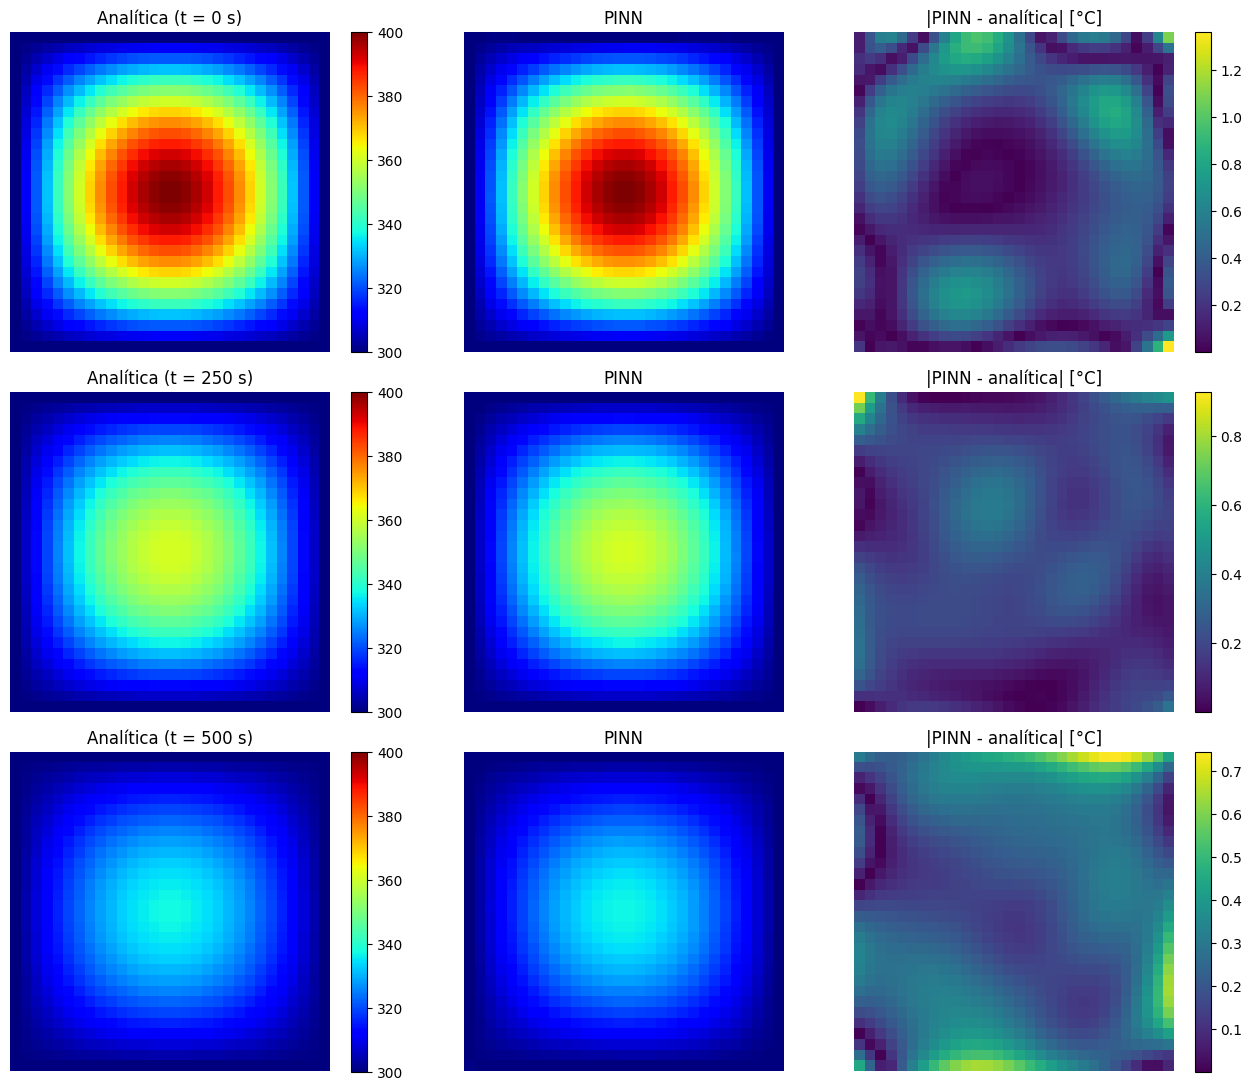

Error máximo [°C] en cada tiempo: [1.362 1.08  0.836 0.64  0.805 0.928 0.971 0.925 0.792 0.647 0.745]


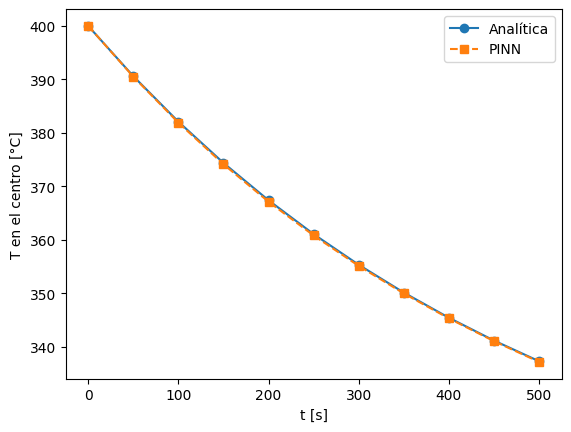

In [24]:
def pinn_T(Xg, Yg, tt):      # tt en segundos; devuelve la temperatura en °C
    xs = torch.tensor((Xg / params["Lx"]).reshape(-1, 1), dtype=torch.float32)
    ys = torch.tensor((Yg / params["Ly"]).reshape(-1, 1), dtype=torch.float32)
    ts = torch.full_like(xs, tt / tf)
    with torch.no_grad():
        th = modelo_pinn(xs, ys, ts).numpy().reshape(Xg.shape)
    return params["Tb"] + params["delta"] * th

# Mapas: analítica, PINN y error absoluto, en tres tiempos
fig, axs = plt.subplots(3, 3, figsize=(13, 11))
for i, tt in enumerate([0, tf / 2, tf]):
    Ta, Tp = T_analitica(X, Y, tt), pinn_T(X, Y, tt)
    im0 = axs[i, 0].imshow(Ta, cmap="jet", vmin=params["Tb"], vmax=params["Tb"] + params["delta"])
    axs[i, 1].imshow(Tp, cmap="jet", vmin=params["Tb"], vmax=params["Tb"] + params["delta"])
    im2 = axs[i, 2].imshow(np.abs(Tp - Ta), cmap="viridis")
    axs[i, 0].set_title(f"Analítica (t = {tt:.0f} s)")
    axs[i, 1].set_title("PINN")
    axs[i, 2].set_title("|PINN - analítica| [°C]")
    fig.colorbar(im0, ax=axs[i, 0]); fig.colorbar(im2, ax=axs[i, 2])
    for ax in axs[i]: ax.axis("off")
plt.tight_layout(); plt.show()

# Error máximo en el tiempo y temperatura en el centro
tiempos = np.linspace(0, tf, 11)
err = [np.abs(pinn_T(X, Y, tt) - T_analitica(X, Y, tt)).max() for tt in tiempos]
print("Error máximo [°C] en cada tiempo:", np.round(err, 3))

centro = lambda f: [f(np.array([[0.5*params["Lx"]]]), np.array([[0.5*params["Ly"]]]), tt)[0, 0] for tt in tiempos]
plt.plot(tiempos, centro(lambda a, b, c: T_analitica(a, b, c)), "o-", label="Analítica")
plt.plot(tiempos, centro(pinn_T), "s--", label="PINN")
plt.xlabel("t [s]"); plt.ylabel("T en el centro [°C]"); plt.legend(); plt.show()